## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', 120)

df = pd.read_csv('amazonreviews.tsv', sep='\t')
df.head()

,label,review
0,pos,Stuning even for the non-gamer: This sound track was beautiful! It paints the senery in your mind so well I would re...
1,pos,The best soundtrack ever to anything.: I'm reading a lot of reviews saying that this is the best 'game soundtrack' a...
2,pos,"Amazing!: This soundtrack is my favorite music of all time, hands down. The intense sadness of ""Prisoners of Fate"" (..."
3,pos,Excellent Soundtrack: I truly like this soundtrack and I enjoy video game music. I have played this game and most of...
4,pos,"Remember, Pull Your Jaw Off The Floor After Hearing it: If you've played the game, you know how divine the music is!..."


In [2]:
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
df.info()

Dataset shape: (10000, 2)
Columns: ['label', 'review']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   10000 non-null  object
 1   review  10000 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB


## 2. Check missing values and duplicates

In [3]:
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Label values:', df['label'].value_counts(dropna=False))

label     0
review    0
dtype: int64
Duplicate rows: 0
Label values: label
neg    5097
pos    4903
Name: count, dtype: int64


In [4]:
df = df.dropna(subset=['label', 'review']).copy()
df['label'] = df['label'].str.strip().str.lower()
df['review'] = df['review'].astype(str).str.strip()
df = df[df['label'].isin(['pos', 'neg'])]
df = df[df['review'] != '']
df = df.drop_duplicates().reset_index(drop=True)

print('Shape after cleaning:', df.shape)
print(df['label'].value_counts())

Shape after cleaning: (10000, 2)
label
neg    5097
pos    4903
Name: count, dtype: int64


## 3. Explore the reviews

label
neg    5097
pos    4903
Name: count, dtype: int64
label
neg    50.97
pos    49.03
Name: count, dtype: float64


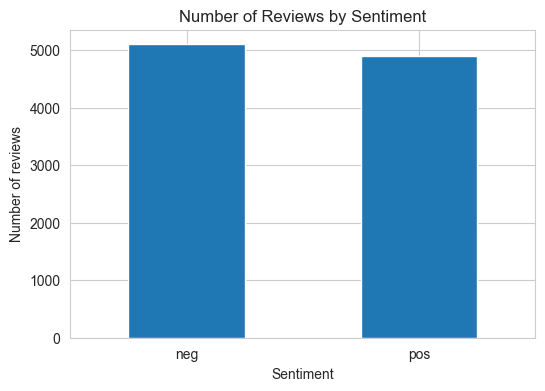

In [5]:
label_counts = df['label'].value_counts().reindex(['neg', 'pos'])
print(label_counts)
print((label_counts / len(df) * 100).round(2))

label_counts.plot(kind='bar', figsize=(6, 4))
plt.title('Number of Reviews by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of reviews')
plt.xticks(rotation=0)
plt.show()

In [6]:
df['review_length'] = df['review'].str.len()
df['word_count'] = df['review'].str.split().str.len()
df[['review_length', 'word_count']].describe()

,review_length,word_count
count,10000.000000,10000.000000
mean,438.695400,79.553100
std,239.241132,43.023225
min,101.000000,14.000000
25%,238.000000,43.000000
50%,391.000000,71.000000
75%,605.000000,109.000000
max,1015.000000,212.000000


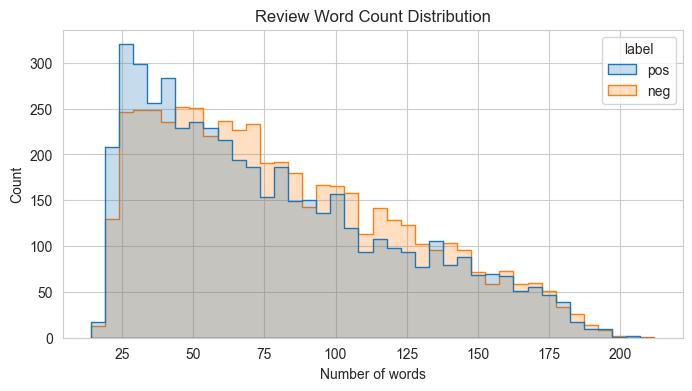

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='word_count', hue='label', bins=40, element='step', stat='count', common_norm=False)
plt.title('Review Word Count Distribution')
plt.xlabel('Number of words')
plt.show()

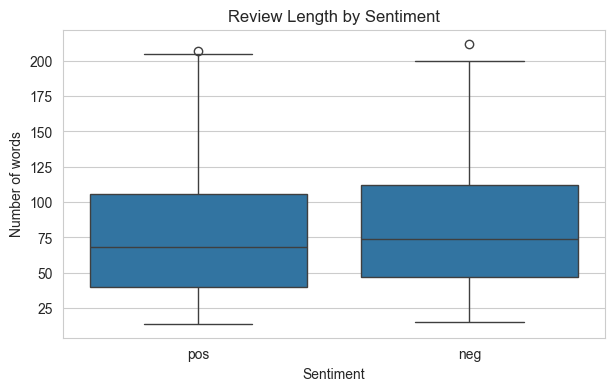

In [8]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='label', y='word_count')
plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of words')
plt.show()

## 4. Clean the text

In [9]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r"[^a-z\s']", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_review'] = df['review'].apply(clean_text)
df[['label', 'review', 'clean_review']].head()

,label,review,clean_review
0,pos,Stuning even for the non-gamer: This sound track was beautiful! It paints the senery in your mind so well I would re...,stuning even for the non gamer this sound track was beautiful it paints the senery in your mind so well i would reco...
1,pos,The best soundtrack ever to anything.: I'm reading a lot of reviews saying that this is the best 'game soundtrack' a...,the best soundtrack ever to anything i'm reading a lot of reviews saying that this is the best 'game soundtrack' and...
2,pos,"Amazing!: This soundtrack is my favorite music of all time, hands down. The intense sadness of ""Prisoners of Fate"" (...",amazing this soundtrack is my favorite music of all time hands down the intense sadness of prisoners of fate which m...
3,pos,Excellent Soundtrack: I truly like this soundtrack and I enjoy video game music. I have played this game and most of...,excellent soundtrack i truly like this soundtrack and i enjoy video game music i have played this game and most of t...
4,pos,"Remember, Pull Your Jaw Off The Floor After Hearing it: If you've played the game, you know how divine the music is!...",remember pull your jaw off the floor after hearing it if you've played the game you know how divine the music is eve...


Stop words are removed during feature extraction. Negation words such as `not`, `no`, `nor`, and `never` are kept because they can change the meaning of a review.

In [10]:
stop_words = set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor', 'never'}
print('Example cleaned review:')
print(df['clean_review'].iloc[0])

Example cleaned review:
stuning even for the non gamer this sound track was beautiful it paints the senery in your mind so well i would recomend it even to people who hate vid game music i have played the game chrono cross but out of all of the games i have ever played it has the best music it backs away from crude keyboarding and takes a fresher step with grate guitars and soulful orchestras it would impress anyone who cares to listen


## 5. Common words in positive and negative reviews

In [11]:
def common_words(texts, n=15):
    vectorizer = CountVectorizer(stop_words=sorted(stop_words), min_df=2)
    matrix = vectorizer.fit_transform(texts)
    totals = np.asarray(matrix.sum(axis=0)).ravel()
    words = vectorizer.get_feature_names_out()
    order = totals.argsort()[::-1][:n]
    return pd.DataFrame({'word': words[order], 'count': totals[order]})

positive_words = common_words(df.loc[df['label'] == 'pos', 'clean_review'])
negative_words = common_words(df.loc[df['label'] == 'neg', 'clean_review'])
print('Positive review words')
display(positive_words)
print('Negative review words')
display(negative_words)

Positive review words


,word,count
0,book,3390
1,great,2135
2,not,1963
3,good,1667
4,read,1605
5,like,1290
6,movie,1121
7,just,1036
8,time,924
9,love,911


Negative review words


,word,count
0,not,4449
1,book,3277
2,like,1569
3,just,1526
4,movie,1519
5,no,1258
6,read,1222
7,good,1160
8,don,1135
9,time,1072


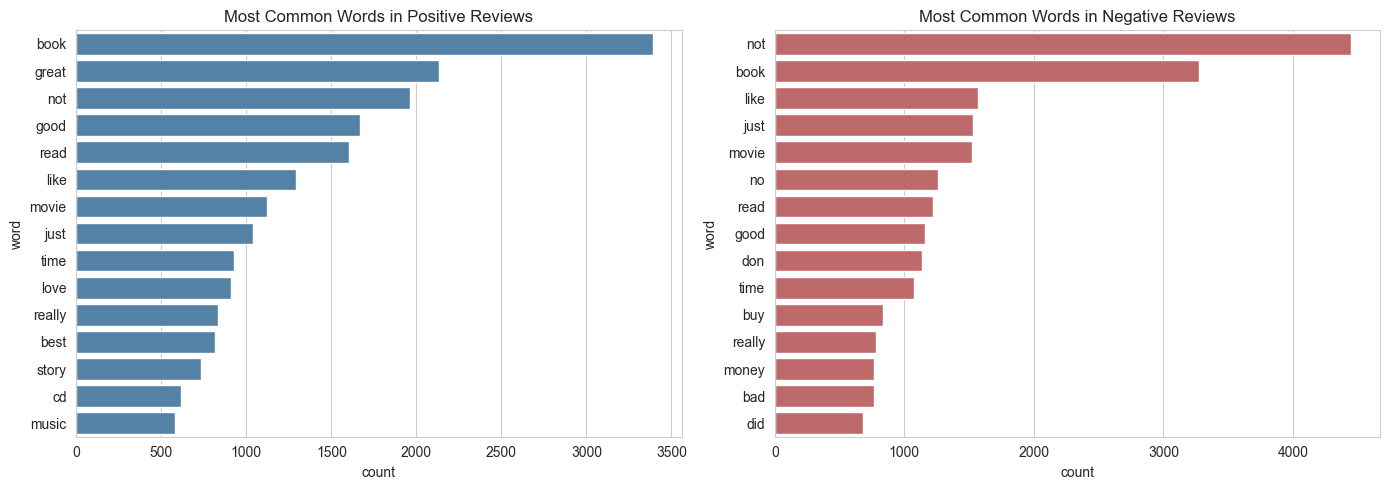

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=positive_words, x='count', y='word', ax=axes[0], color='steelblue')
axes[0].set_title('Most Common Words in Positive Reviews')
sns.barplot(data=negative_words, x='count', y='word', ax=axes[1], color='indianred')
axes[1].set_title('Most Common Words in Negative Reviews')
plt.tight_layout()
plt.show()

## 6. Word clouds

In [13]:
try:
    from wordcloud import WordCloud
    wordcloud_available = True
except ImportError:
    wordcloud_available = False

if wordcloud_available:
    positive_text = ' '.join(df.loc[df['label'] == 'pos', 'clean_review'])
    negative_text = ' '.join(df.loc[df['label'] == 'neg', 'clean_review'])
    positive_cloud = WordCloud(width=900, height=450, background_color='white', stopwords=stop_words, collocations=False).generate(positive_text)
    negative_cloud = WordCloud(width=900, height=450, background_color='white', stopwords=stop_words, collocations=False).generate(negative_text)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    axes[0].imshow(positive_cloud, interpolation='bilinear')
    axes[0].set_title('Positive Reviews')
    axes[0].axis('off')
    axes[1].imshow(negative_cloud, interpolation='bilinear')
    axes[1].set_title('Negative Reviews')
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('WordCloud is not installed. Run %pip install wordcloud to create this plot.')

WordCloud is not installed. Run %pip install wordcloud to create this plot.


## 7. Split the data

In [14]:
X = df['clean_review']
y = df['label'].map({'neg': 0, 'pos': 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))
print('Training label balance:')
print(y_train.value_counts(normalize=True).round(3))

Training samples: 8000
Testing samples: 2000
Training label balance:
label
0    0.51
1    0.49
Name: proportion, dtype: float64


## 8. Build a TF-IDF and Logistic Regression model

In [15]:
model = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words=sorted(stop_words), max_features=20000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Score': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})
results.round(4)

,Metric,Score
0,Accuracy,0.8660
1,Precision,0.8664
2,Recall,0.8593
3,F1-score,0.8628
4,ROC-AUC,0.9342


In [16]:
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.87      0.87      0.87      1019
    Positive       0.87      0.86      0.86       981

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



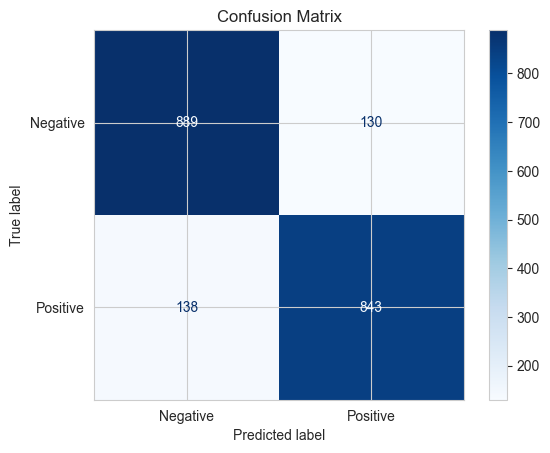

In [17]:
cm = confusion_matrix(y_test, y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
cm_display.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix')
plt.show()

## 9. Cross-validation and hyperparameter tuning

In [18]:
parameters = {
    'classifier__C': [0.5, 1.0, 2.0]
}

grid = GridSearchCV(
    model,
    parameters,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best cross-validation F1-score:', round(grid.best_score_, 4))

Best parameters: {'classifier__C': 2.0}
Best cross-validation F1-score: 0.8662


In [19]:
tuned_model = grid.best_estimator_
tuned_pred = tuned_model.predict(X_test)
tuned_prob = tuned_model.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Default model': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ],
    'Tuned model': [
        accuracy_score(y_test, tuned_pred),
        precision_score(y_test, tuned_pred),
        recall_score(y_test, tuned_pred),
        f1_score(y_test, tuned_pred),
        roc_auc_score(y_test, tuned_prob)
    ]
})
comparison.round(4)

,Metric,Default model,Tuned model
0,Accuracy,0.8660,0.8655
1,Precision,0.8664,0.8655
2,Recall,0.8593,0.8593
3,F1-score,0.8628,0.8624
4,ROC-AUC,0.9342,0.9370


In [20]:
print(classification_report(y_test, tuned_pred, target_names=['Negative', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.87      0.87      0.87      1019
    Positive       0.87      0.86      0.86       981

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



## 10. Important words learned by the model

In [21]:
tfidf = tuned_model.named_steps['tfidf']
classifier = tuned_model.named_steps['classifier']
feature_names = tfidf.get_feature_names_out()
coefficients = classifier.coef_[0]

positive_indices = np.argsort(coefficients)[-15:][::-1]
negative_indices = np.argsort(coefficients)[:15]

important_positive = pd.DataFrame({
    'word': feature_names[positive_indices],
    'coefficient': coefficients[positive_indices]
})
important_negative = pd.DataFrame({
    'word': feature_names[negative_indices],
    'coefficient': coefficients[negative_indices]
})

print('Words associated with positive sentiment')
display(important_positive)
print('Words associated with negative sentiment')
display(important_negative)

Words associated with positive sentiment


,word,coefficient
0,great,8.737911
1,excellent,6.192141
2,best,5.548230
3,love,5.228946
4,perfect,4.901887
5,good,4.882682
6,wonderful,3.943599
7,amazing,3.910499
8,favorite,3.690746
9,easy,3.629178


Words associated with negative sentiment


,word,coefficient
0,not,-8.936699
1,boring,-6.613082
2,poor,-5.695715
3,bad,-5.601708
4,worst,-5.559509
5,disappointed,-5.297572
6,waste,-5.044581
7,disappointing,-4.347178
8,money,-3.898154
9,don,-3.834178


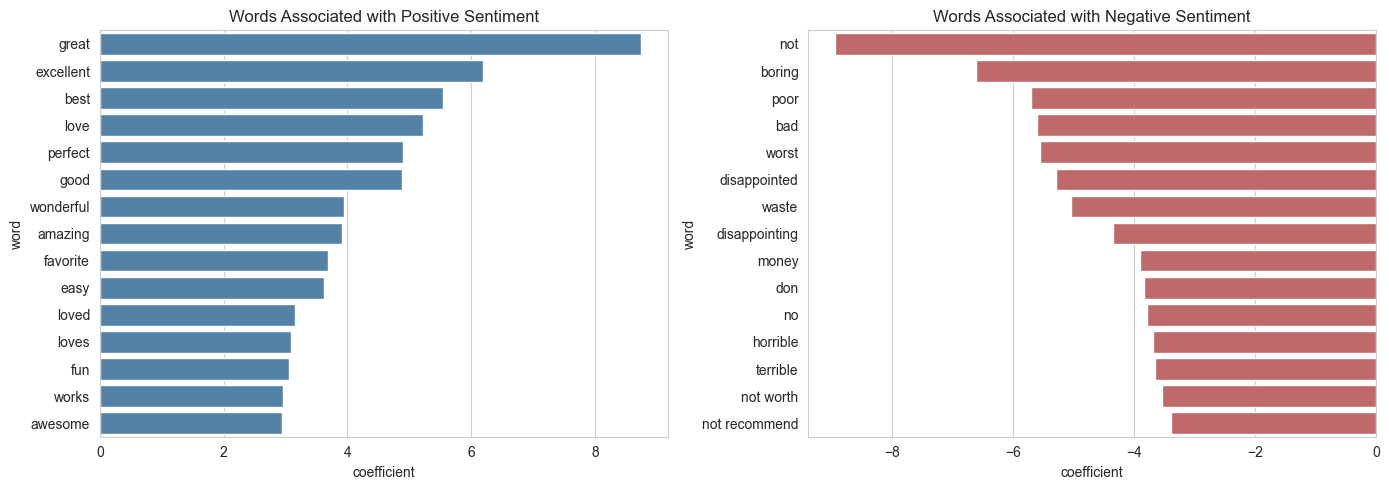

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=important_positive, x='coefficient', y='word', ax=axes[0], color='steelblue')
axes[0].set_title('Words Associated with Positive Sentiment')
sns.barplot(data=important_negative, x='coefficient', y='word', ax=axes[1], color='indianred')
axes[1].set_title('Words Associated with Negative Sentiment')
plt.tight_layout()
plt.show()

## 11. Test the model on example reviews

In [23]:
examples = [
    'This product is excellent and works perfectly.',
    'This was a terrible purchase and I am very disappointed.',
    'The quality is not good and I would not recommend it.'
]
example_predictions = tuned_model.predict(examples)
example_results = pd.DataFrame({
    'Review': examples,
    'Predicted sentiment': ['Positive' if value == 1 else 'Negative' for value in example_predictions]
})
example_results

,Review,Predicted sentiment
0,This product is excellent and works perfectly.,Positive
1,This was a terrible purchase and I am very disappointed.,Negative
2,The quality is not good and I would not recommend it.,Negative


## 12. Conclusion

In [26]:
best_f1 = comparison.loc[comparison['Metric'] == 'F1-score'].iloc[0]
print('Default model F1-score:', round(best_f1['Default model'], 4))
print('Tuned model F1-score:', round(best_f1['Tuned model'], 4))


Default model F1-score: 0.8628
Tuned model F1-score: 0.8624
